# clasificación de textos con perceptrones multicapa (MLP)


In [132]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils import shuffle
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)



In [133]:
#!conda create -y -n ia_nlp python=3.11 numpy=1.26.4 pandas matplotlib seaborn scikit-learn tensorflow ipykernel

## Dataset artificial

In [134]:
datos = {
    "texto": [
        # Deportes
        "El equipo ganó el campeonato nacional de fútbol",
        "La selección anotó tres goles durante el partido",
        "El atleta obtuvo medalla en carrera de velocidad",
        "El entrenador diseñó una estrategia para el torneo",
        "Los jugadores entrenaron para la final de baloncesto",
        "La nadadora rompió el récord en la competencia",
        "El tenista ganó el primer set del abierto",
        "La gimnasta ejecutó una rutina perfecta en la final",
        "El portero atajó un penal en el último minuto",
        "La escudería presentó su nuevo automóvil de carreras",
        "El boxeador defendió su título mundial en el cuadrilátero",
        "Los aficionados llenaron el estadio para el clásico",
        "La corredora cruzó la meta en primer lugar",
        "El equipo de voleibol clasificó a las semifinales",
        "El defensa recibió una tarjeta amarilla por falta",
        "La delegación nacional viajó a los juegos panamericanos",
        "El capitán levantó el trofeo tras la victoria",
        "Los ciclistas recorrieron cien kilómetros en la ruta",
        "El delantero marcó un gol de cabeza en el área",
        "La federación anunció el calendario de la liga",
        "El golfista completó el recorrido bajo el par",
        "La esgrimista ganó el combate decisivo por puntos",
        "El entrenador realizó tres cambios en el segundo tiempo",
        "Los atletas participaron en el maratón de la ciudad",
        "El equipo local empató el encuentro sin goles",
        "La levantadora de pesas superó su marca personal",
        "El árbitro revisó la jugada en el videoarbitraje",
        "La selección femenina avanzó a la siguiente ronda",
        "El judoca obtuvo la victoria por ippon en el tatami",
        "Los nadadores compitieron en la prueba de relevos",
        "El club renovó el contrato de su director técnico",
        "La patinadora artística brilló en la pista de hielo",
        "El lanzador consiguió diez ponches en el juego de béisbol",
        "La arquera acertó en el centro de la diana",
        "El equipo visitante sufrió una derrota en la jornada",
        "Los remeros cruzaron el lago a gran velocidad",
        "El mediocampista dio dos asistencias durante el encuentro",
        "La triatleta completó la prueba de natación y ciclismo",
        "El comité organizador inauguró la villa olímpica",
        "Los jugadores celebraron el ascenso a primera división",
        "El saltador alcanzó una distancia histórica en longitud",
        "La luchadora ganó el combate en el tercer asalto",
        "El torneo internacional reunió a treinta selecciones",
        "Los fanáticos apoyaron al equipo desde las gradas",
        "La clavadista recibió altas calificaciones de los jueces",
        "El piloto logró la mejor vuelta en la clasificación",
        "El equipo juvenil ganó la copa regional de atletismo",
        "La jugadora de tenis avanzó a los cuartos de final",
        "El preparador físico evaluó el rendimiento del plantel",
        "Los deportistas recibieron un reconocimiento por sus logros",

        # Política
        "El congreso aprobó una reforma electoral",
        "La presidenta anunció nuevas políticas públicas",
        "El gobierno debatió el presupuesto nacional",
        "Los partidos iniciaron la campaña para las elecciones",
        "El senador presentó una propuesta legislativa",
        "La ciudadanía participó en la consulta popular",    
        "El gabinete discutió cambios en la administración pública",
        "La comisión revisó la ley de transparencia",
        "El candidato explicó su programa de gobierno",
        "El parlamento aprobó nuevas medidas económicas",
        "La diputada propuso una iniciativa de seguridad social",
        "El tribunal electoral validó los resultados de los comicios",
        "Los gobernadores se reunieron para evaluar el pacto fiscal",
        "El ministerio publicó el informe anual de gestión",
        "La oposición cuestionó la reforma energética en el pleno",
        "Los ciudadanos acudieron a las urnas desde temprano",
        "El alcalde presentó el plan de desarrollo municipal",
        "La secretaría de hacienda ajustó el gasto público",
        "El poder ejecutivo envió el decreto al senado",
        "Los legisladores votaron a favor del dictamen",
        "La coalición definió a su representante para la contienda",
        "El consejo nacional organizó el debate presidencial",
        "La bancada mayoritaria respaldó la reforma educativa",
        "El mandatario firmó un acuerdo de cooperación internacional",
        "La comisión de justicia analizó las modificaciones al código",
        "Los electores evaluaron las propuestas de cada candidato",
        "El estado garantizó la imparcialidad del proceso electoral",
        "La cámara baja aprobó la ley de ingresos",
        "El partido gobernante celebró su asamblea nacional",
        "La diplomacia bilateral fortaleció las relaciones exteriores",
        "El observatorio ciudadano supervisó la jornada de votación",
        "Los ministros acordaron estrategias para el desarrollo regional",
        "La contraloría auditó los recursos de las dependencias",
        "El vocero oficial informó sobre las decisiones del gabinete",
        "La asamblea constituyente redactó nuevos artículos legales",
        "Los representantes populares rindieron su informe de labores",
        "El organismo autónomo presentó el padrón electoral actualizado",
        "La reforma constitucional recibió el respaldo de los estados",
        "El líder parlamentario convocó a una sesión extraordinaria",
        "La política exterior priorizó los tratados comerciales",
        "Los concejales aprobaron el reglamento de participación ciudadana",
        "El instituto electoral reguló los tiempos en medios de comunicación",
        "La jefatura de gobierno impulsó programas de bienestar social",
        "Los candidatos firmaron un pacto de civilidad democrática",
        "El senado ratificó el nombramiento de los embajadores",
        "La legislación vigente establece normas para el financiamiento",
        "El foro político analizó los retos de la gobernabilidad",
        "Los votantes exigieron mayor rendición de cuentas",
        "El ejecutivo promulgó la ley en el diario oficial",
        "La mesa directiva clausuró el periodo ordinario de sesiones",

        # Arte
        "La artista inauguró una exposición de pintura",
        "El museo presentó esculturas de arte contemporáneo",
        "El músico interpretó una composición en el festival",
        "La galería exhibió obras de artistas mexicanos",
        "El pintor utilizó colores para crear un mural",
        "La bailarina presentó una coreografía clásica",
        "El escritor publicó una novela sobre la cultura",
        "La orquesta ofreció un concierto de música clásica",
        "El escultor creó una obra para la exposición",
        "El festival celebró el teatro y las artes visuales",
        "La fotógrafa presentó una serie en blanco y negro",
        "El teatro estrenó una obra dramática este fin de semana",
        "La poeta recitó sus versos en la feria del libro",
        "El director de cine ganó un premio por su documental",
        "La ceramista moldeó piezas inspiradas en la tradición",
        "El coro interpretó cantos tradicionales en el auditorio",
        "La ilustración digital cobró protagonismo en la muestra",
        "El arquitecto diseñó un pabellón de estilo minimalista",
        "La dramaturga escribió un guion sobre la historia local",
        "El violonchelista ofreció un recital en la sala principal",
        "La fundación cultural otorgó becas a jóvenes creadores",
        "El taller de grabado enseñó técnicas sobre madera y metal",
        "La compañía de danza estrenó un espectáculo moderno",
        "El curador seleccionó las piezas para la bienal de arte",
        "La soprano recibió aplausos tras su actuación en la ópera",
        "El muralista pintó una fachada en el centro histórico",
        "La editorial lanzó una antología de cuentos contemporáneos",
        "El guitarrista compuso una melodía acústica original",
        "La colección privada incluye lienzos del siglo diecinueve",
        "El centro cultural organizó un ciclo de cine independiente",
        "La diseñadora textil creó tapices con tintes naturales",
        "El cuarteto de cuerdas tocó piezas de compositores barrocos",
        "La crítica elogió la estética de la nueva instalación",
        "El actor protagonizó un monólogo en el escenario",
        "La academia de bellas artes abrió sus inscripciones anuales",
        "El artesano talló figuras detalladas en madera de cedro",
        "La revista literaria publicó ensayos sobre estética visual",
        "El pianista ejecutó una sonata durante la gala benéfica",
        "La muestra fotográfica retrata paisajes urbanos y rurales",
        "El colectivo artístico intervino espacios públicos con color",
        "La novela histórica recibió el reconocimiento de la crítica",
        "El conservatorio celebró el talento de sus estudiantes",
        "La exposición itinerante recorrerá varias ciudades del país",
        "El caricaturista publicó sus ilustraciones en el periódico",
        "La obra teatral combinó música en vivo y actuación",
        "El artista plástico experimentó con materiales reciclados",
        "La biblioteca alberga manuscritos antiguos de gran valor",
        "El festival de jazz reunió a músicos internacionales",
        "La escultura de bronce fue colocada en la plaza principal",
        "El ensayo filosófico analiza el impacto del arte moderno",
        "La escultura fue restaurada y devuelta a su ubicación original",
        "La exposición de arte contemporáneo atrajo a miles de visitantes"
    ],
    "categoria": (
        ["Deportes"] * 50 +
        ["Politica"] * 50 +
        ["Arte"] * 52
    )
}

df = pd.DataFrame(datos)

print("Total de frases:", len(df))
print(df["categoria"].value_counts())
display(df[1:150:10])


Total de frases: 152
categoria
Arte        52
Deportes    50
Politica    50
Name: count, dtype: int64


,texto,categoria
1,La selección anotó tres goles durante el partido,Deportes
11,Los aficionados llenaron el estadio para el cl...,Deportes
21,La esgrimista ganó el combate decisivo por puntos,Deportes
31,La patinadora artística brilló en la pista de ...,Deportes
41,La luchadora ganó el combate en el tercer asalto,Deportes
51,La presidenta anunció nuevas políticas públicas,Politica
61,El tribunal electoral validó los resultados de...,Politica
71,El consejo nacional organizó el debate preside...,Politica
81,Los ministros acordaron estrategias para el de...,Politica
91,El instituto electoral reguló los tiempos en m...,Politica


In [135]:
datos2 = {
    "texto": [
        # Deportes
        "El equipo ganó el campeonato nacional de fútbol",
        "La selección anotó tres goles durante el partido",
        "El atleta obtuvo medalla en carrera de velocidad",
        "El entrenador diseñó una estrategia para el torneo",
        "Los jugadores entrenaron para la final de baloncesto",
        "La nadadora rompió el récord en la competencia",
        "El árbitro suspendió el encuentro por lluvia",
        "El club contrató un delantero para la temporada",
        "La ciclista ganó la etapa de montaña",
        "El equipo olímpico inició su preparación deportiva",

        # Política
        "El congreso aprobó una reforma electoral",
        "La presidenta anunció nuevas políticas públicas",
        "El gobierno debatió el presupuesto nacional",
        "Los partidos iniciaron la campaña para las elecciones",
        "El senador presentó una propuesta legislativa",
        "La ciudadanía participó en la consulta popular",
        "El gabinete discutió cambios en la administración pública",
        "La comisión revisó la ley de transparencia",
        "El candidato explicó su programa de gobierno",
        "El parlamento aprobó nuevas medidas económicas",

        # Arte
        "La artista inauguró una exposición de pintura",
        "El museo presentó esculturas de arte contemporáneo",
        "El músico interpretó una composición en el festival",
        "La galería exhibió obras de artistas mexicanos",
        "El pintor utilizó colores para crear un mural",
        "La bailarina presentó una coreografía clásica",
        "El escritor publicó una novela sobre la cultura",
        "La orquesta ofreció un concierto de música clásica",
        "El escultor creó una obra para la exposición",
        "El festival celebró el teatro y las artes visuales"
    ],
    "categoria": (
        ["Deportes"] * 10 +
        ["Politica"] * 10 +
        ["Arte"] * 10
    )
}

df = pd.DataFrame(datos)

print("Total de frases:", len(df))
print(df["categoria"].value_counts())
display(df)


Total de frases: 152
categoria
Arte        52
Deportes    50
Politica    50
Name: count, dtype: int64


,texto,categoria
0,El equipo ganó el campeonato nacional de fútbol,Deportes
1,La selección anotó tres goles durante el partido,Deportes
2,El atleta obtuvo medalla en carrera de velocidad,Deportes
3,El entrenador diseñó una estrategia para el to...,Deportes
4,Los jugadores entrenaron para la final de balo...,Deportes
...,...,...
147,El festival de jazz reunió a músicos internaci...,Arte
148,La escultura de bronce fue colocada en la plaz...,Arte
149,El ensayo filosófico analiza el impacto del ar...,Arte
150,La escultura fue restaurada y devuelta a su ub...,Arte


In [136]:
stopwords_es = {
    "el", "la", "los", "las", "un", "una", "unos", "unas",
    "de", "del", "al", "y", "o", "en", "durante", "para",
    "por", "con", "que", "se", "su", "sus", "es", "fue", "a"
}

def limpiar_texto(texto):
    texto = texto.lower()
    texto = re.sub(r"[^a-záéíóúüñ\s]", " ", texto)
    tokens = texto.split()
    tokens = [p for p in tokens if p not in stopwords_es]
    return " ".join(tokens)

df["texto_limpio"] = df["texto"].apply(limpiar_texto)
display(df[["categoria", "texto", "texto_limpio"]])


,categoria,texto,texto_limpio
0,Deportes,El equipo ganó el campeonato nacional de fútbol,equipo ganó campeonato nacional fútbol
1,Deportes,La selección anotó tres goles durante el partido,selección anotó tres goles partido
2,Deportes,El atleta obtuvo medalla en carrera de velocidad,atleta obtuvo medalla carrera velocidad
3,Deportes,El entrenador diseñó una estrategia para el to...,entrenador diseñó estrategia torneo
4,Deportes,Los jugadores entrenaron para la final de balo...,jugadores entrenaron final baloncesto
...,...,...,...
147,Arte,El festival de jazz reunió a músicos internaci...,festival jazz reunió músicos internacionales
148,Arte,La escultura de bronce fue colocada en la plaz...,escultura bronce colocada plaza principal
149,Arte,El ensayo filosófico analiza el impacto del ar...,ensayo filosófico analiza impacto arte moderno
150,Arte,La escultura fue restaurada y devuelta a su ub...,escultura restaurada devuelta ubicación original


## Codificar las etiquetas

Convertir las categorías de texto en valores enteros. Consultar classes_ para conocer la correspondencia asignada.

In [137]:
encoder = LabelEncoder()
y = encoder.fit_transform(df["categoria"])

for numero, categoria in enumerate(encoder.classes_):
    print(f"{categoria}: {numero}")

Arte: 0
Deportes: 1
Politica: 2


## Separar entrenamiento y prueba

In [138]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["texto"],
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Entrenamiento:", len(X_train_text))
print("Prueba:", len(X_test_text))

print("Clases en entrenamiento:")
print(pd.Series(encoder.inverse_transform(y_train)).value_counts())

print("Clases en prueba:")
print(pd.Series(encoder.inverse_transform(y_test)).value_counts())

Entrenamiento: 121
Prueba: 31
Clases en entrenamiento:
Arte        41
Politica    40
Deportes    40
Name: count, dtype: int64
Clases en prueba:
Arte        11
Politica    10
Deportes    10
Name: count, dtype: int64


# Generar las representaciones BoW y TF-IDF

* CountVectorizer cuenta las apariciones de cada término. 
* TfidfVectorizer pondera los términos según su frecuencia en el documento y su distribución en el corpus.



In [139]:
vectorizadores = {
    "BoW": CountVectorizer(
        preprocessor=limpiar_texto,
        tokenizer=str.split,
        token_pattern=None,
        lowercase=False
    ),
    "TF-IDF": TfidfVectorizer(
        preprocessor=limpiar_texto,
        tokenizer=str.split,
        token_pattern=None,
        lowercase=False
    )
}

matrices = {}

for nombre, vectorizador in vectorizadores.items():
    # Ajustar solo con entrenamiento
    X_train = vectorizador.fit_transform(X_train_text)

    # Transformar prueba usando el vocabulario aprendido
    X_test = vectorizador.transform(X_test_text)

    matrices[nombre] = (X_train, X_test)

    print(f"\n{nombre}")
    print("Vocabulario:", len(vectorizador.vocabulary_))
    print("Matriz de entrenamiento:", X_train.shape)
    print("Matriz de prueba:", X_test.shape)
    print("Términos:", vectorizador.get_feature_names_out()[:10])  # Mostrar solo los primeros 10 términos



BoW
Vocabulario: 520
Matriz de entrenamiento: (121, 520)
Matriz de prueba: (31, 520)
Términos: ['abrió' 'academia' 'acertó' 'acordaron' 'actor' 'actuación' 'actualizado'
 'acudieron' 'acuerdo' 'acústica']

TF-IDF
Vocabulario: 520
Matriz de entrenamiento: (121, 520)
Matriz de prueba: (31, 520)
Términos: ['abrió' 'academia' 'acertó' 'acordaron' 'actor' 'actuación' 'actualizado'
 'acudieron' 'acuerdo' 'acústica']


In [140]:
X_bow_train, X_bow_test = matrices["BoW"]

df_bow = pd.DataFrame(
    X_bow_train.toarray(),
    columns=vectorizadores["BoW"].get_feature_names_out(),
    index=X_train_text.index
)

df_bow.head(10).T

,106,135,85,83,45,56,123,42,81,24
abrió,0,0,0,0,0,0,0,0,0,0
academia,0,0,0,0,0,0,0,0,0,0
acertó,0,0,0,0,0,0,0,0,0,0
acordaron,0,0,0,0,0,0,0,0,1,0
actor,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...
vuelta,0,0,0,0,1,0,0,0,0,0
árbitro,0,0,0,0,0,0,0,0,0,0
área,0,0,0,0,0,0,0,0,0,0
ópera,0,0,0,0,0,0,0,0,0,0


### Evaluación 

In [141]:
resultados = []
historicos = {}

def evaluar_modelo(nombre, y_real, y_pred):
    resultados.append({
        "Experimento": nombre,
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(
            y_real, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_real, y_pred, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_real, y_pred, average="macro", zero_division=0
        )
    })

    print(f"\n ===== =====  {nombre} ")
    print(classification_report(
        y_real,
        y_pred,
        labels=np.arange(len(encoder.classes_)),
        target_names=encoder.classes_,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_real, y_pred,
        labels=np.arange(len(encoder.classes_))
    )

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=encoder.classes_,
        yticklabels=encoder.classes_
    )
    plt.title(f"Matriz de confusión: {nombre}")
    plt.xlabel("Predicción")
    plt.ylabel("Categoría real")
    plt.tight_layout()
    plt.show()


## MLP: Scikit-learn

* `hidden_layer_sizes=(32, 16)*: Define la arquitectura interna de la red. Crea dos capas ocultas, en este ejemplo, la primera tiene 32 neuronas y la segunda tiene 16 neuronas.
* `activation="relu": Es la función matemática que decide si una neurona se "activa" o no. ReLU (Rectified Linear Unit) convierte cualquier valor negativo en cero y deja pasar los positivos, lo que hace que el entrenamiento sea rápido y eficiente.
* `solver="adam": Es el algoritmo de optimización encargado de ajustar los pesos de la red para reducir los errores. Adam  adapta automáticamente la velocidad de aprendizaje durante el proceso.
* `learning_rate_init=0.01: Es la tasa de aprendizaje inicial. Controla qué tan grandes son los "pasos" que da el modelo al corregir sus errores; 0.01 es un paso relativamente rápido.
* `batch_size=4: Indica cuántos ejemplos de entrenamiento procesa la red antes de actualizar sus pesos. En este caso, lee 4 registros a la vez y ajusta sus cálculos.
* `max_iter=1: Define cuántas veces completas (épocas) recorrerá el modelo todo el conjunto de datos de entrenamiento. Al estar en 1, el modelo solo dará una sola pasada por los datos. (Nota: Esto se suele usar cuando se entrena paso a paso dentro de un bucle for usando .partial_fit(), ya que una sola pasada normal no basta para que aprenda bien).
* `random_state=SEED: Fija una semilla aleatoria (un número entero guardado en la variable SEED). Esto garantiza que, cada vez que ejecutes el código, los pesos iniciales se generen igual y obtengas exactamente los mismos resultados.

In [142]:
def entrenar_sklearn(X_train, y_train, X_test, y_test, nombre, h1=32, h2=16, lr=0.01, batch_size=4, max_iter=1, epocas=100):
    modelo = MLPClassifier(
        hidden_layer_sizes=(h1, h2),
        activation="relu",
        solver="adam",
        learning_rate_init=lr,
        batch_size=batch_size,
        max_iter=max_iter,
        random_state=SEED
    )

    historial_loss = []
    historial_accuracy = []
    clases = np.arange(len(encoder.classes_))

    for epoca in range(epocas):
        
        # Mezclar datos en cada época mejora la convergencia
        X_shuffled, y_shuffled = shuffle(
            X_train, y_train, random_state=SEED + epoca
        )

        modelo.partial_fit(
            X_shuffled,
            y_shuffled,
            classes=clases if epoca == 0 else None
        )

        pred_train = modelo.predict(X_train)
        historial_loss.append(modelo.loss_)
        historial_accuracy.append(
            accuracy_score(y_train, pred_train)
        )

    pred_test = modelo.predict(X_test)

    historicos[nombre] = {
        "loss": historial_loss,
        "accuracy": historial_accuracy
    }

    evaluar_modelo(nombre, y_test, pred_test)
    return modelo


In [143]:
def construir_mlp_keras(n_caracteristicas, h1=32, h2=16, lr=0.01):
    modelo = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(n_caracteristicas,)),
        tf.keras.layers.Dense(h1, activation="relu"),
        tf.keras.layers.Dense(h2, activation="relu"),
        tf.keras.layers.Dense(
            len(encoder.classes_),
            activation="softmax"
        )
    ])

    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return modelo


# Ejecutar los experimentos

Se obtienen cuatro combinaciones: BoW + Scikit-learn, TF-IDF + Scikit-learn, BoW + Keras y TF-IDF + Keras.



## Métricas por categoría (Arte, Deportes, Política)



|               |   precision  |   recall |  f1-score  | support   |
|       ----    |   -----      |   ----   |  ----      |  ----     |
|        Arte   |    0.90      | 0.90     |  0.90      |  10       |
|    Deportes   |    1.00      | 0.70     |  0.82      |  10       |
|    Politica   |    0.69      | 0.90     |  0.78      |  10       |
|    accuracy   |              |          |  0.83      |  30       |
|   macro avg   |    0.86      | 0.83     |  0.84      |  30       |
|weighted avg   |    0.86      | 0.83     |  0.84      |  30       |

Para entender las fórmulas, considera cada clase por separado usando estos términos:
* VP (Verdaderos Positivos): Frases de esa clase que el modelo acertó.
* FP (Falsos Positivos): Frases de otras clases que el modelo etiquetó erróneamente como ésta.
* FN (Falsos Negativos): Frases que sí eran de esta clase, pero el modelo las clasificó en otra.

**Support (Soporte)**

* Qué es: Es la cantidad real de ejemplos de cada categoría en el conjunto de prueba (test).
* En el ejemplo, se evalúan 30 frases en total, repartidas de forma equilibrada con 10 frases de Arte, 10 de Deportes y 10 de Política.

**Precision (Precisión)**

* Qué mide: De todas las veces que el modelo predijo una categoría, ¿qué porcentaje realmente pertenecía a ella? Mide la calidad o confiabilidad de la predicción.
* Fórmula:


$\text{Precision}=\frac{VP}{VP+FP}$


* En el ejemplo:
	* Deportes (1.00): Cuando el modelo dice que una frase es de Deportes, acierta el 100% de las veces (no cometió falsos positivos).
	* Política (0.69): Cuando predice Política, solo acierta el 69% de las veces (el otro 31% eran frases de Deportes o Arte que confundió con Política).



**Recall (Exhaustividad o Sensibilidad)**

* Qué mide: De todas las frases reales que había de una categoría en la prueba, ¿qué porcentaje logró detectar el modelo?
* Fórmula:

$\text{Recall}=\frac{VP}{VP+FN}$

* En el ejemplo:
	* Arte (0.90) y Política (0.90): El modelo encontró 9 de las 10 frases reales de cada una de estas categorías.
	* Deportes (0.70): De las 10 frases reales de Deportes, solo detectó 7; las otras 3 las clasificó erróneamente en otra categoría (probablemente en Política, lo que explica por qué bajó la precisión de Política).

**F1-Score (Puntuación F1)**

* Qué mide: Es el promedio armónico entre Precision y Recall. Resume ambas métricas en un solo número y castiga al modelo si una de las dos es muy baja.
* Fórmula:

$F_{1}=2\times \frac{\text{Precision}\times \text{Recall}}{\text{Precision}+\text{Recall}}$

* En el ejemplo: Arte (0.90) es la clase mejor equilibrada, mientras que Política (0.78) tiene el puntaje más bajo por el exceso de falsos positivos.


## Métricas globales (parte inferior de la tabla)


**Accuracy (Exactitud general)**

* Qué mide: El porcentaje total de aciertos sobre el total de frases evaluadas.
* Fórmula:
  
$\text{Accuracy}=\frac{\text{Total\ de\ predicciones\ correctas}}{\text{Total\ de\ ejemplos}}=\frac{9+7+9}{30}=\frac{25}{30}=0.833\approx 0.83$

**Macro Avg (Promedio Macro)**

* Qué mide: Es el promedio simple de cada métrica sumando las tres clases y dividiendo entre 3. Trata a todas las categorías con exactamente el mismo peso, sin importar cuántos ejemplos tenga cada una.
  
* Fórmulas aplicadas al ejemplo:
	* Macro Precision: $\frac{0.90 + 1.00 + 0.69}{3} = \frac{2.59}{3} = 0.863 \approx 0.86$
	* Macro Recall: $\frac{0.90 + 0.70 + 0.90}{3} = \frac{2.50}{3} = 0.833 \approx 0.83$
	* Macro F1-Score: $\frac{0.90 + 0.82 + 0.78}{3} = \frac{2.50}{3} = 0.833 \approx 0.84$ (calculado con decimales exactos sin redondear)

**Weighted Avg (Promedio Ponderado)**

* Qué mide: Calcula el promedio multiplicando la métrica de cada clase por su support (peso) y dividiendo entre el total de ejemplos.
  
* Por qué es igual al Macro Avg en el ejemplo: Como las tres clases están perfectamente balanceadas (10 ejemplos cada una), cada clase pesa exactamente $\frac{10}{30}$, por lo que ambos promedios dan idéntico resultado (0.86, 0.83, 0.84). 


REPRESENTACIÓN: BoW

 ===== =====  BoW + Scikit-learn 
              precision    recall  f1-score   support

        Arte       0.90      0.82      0.86        11
    Deportes       0.60      0.90      0.72        10
    Politica       0.83      0.50      0.62        10

    accuracy                           0.74        31
   macro avg       0.78      0.74      0.73        31
weighted avg       0.78      0.74      0.74        31



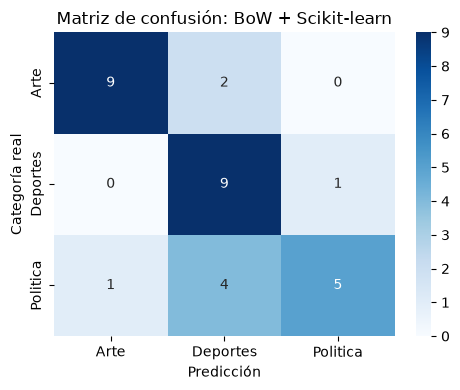


 ===== =====  BoW + Keras 
              precision    recall  f1-score   support

        Arte       0.82      0.82      0.82        11
    Deportes       0.54      0.70      0.61        10
    Politica       0.71      0.50      0.59        10

    accuracy                           0.68        31
   macro avg       0.69      0.67      0.67        31
weighted avg       0.69      0.68      0.68        31



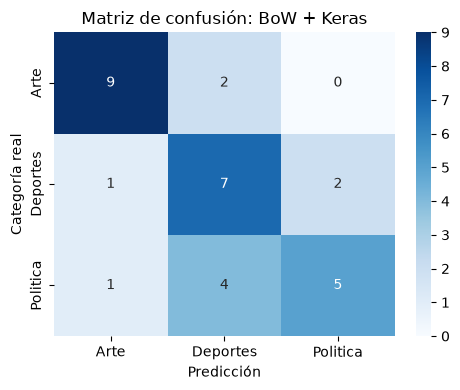


REPRESENTACIÓN: TF-IDF

 ===== =====  TF-IDF + Scikit-learn 
              precision    recall  f1-score   support

        Arte       0.90      0.82      0.86        11
    Deportes       0.60      0.90      0.72        10
    Politica       0.83      0.50      0.62        10

    accuracy                           0.74        31
   macro avg       0.78      0.74      0.73        31
weighted avg       0.78      0.74      0.74        31



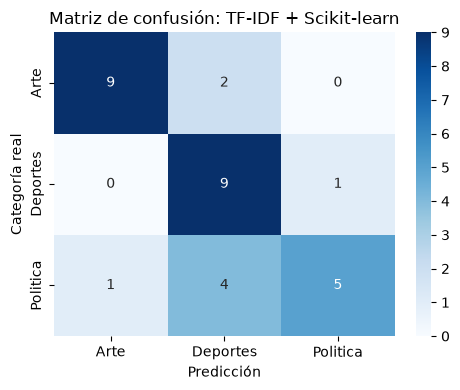


 ===== =====  TF-IDF + Keras 
              precision    recall  f1-score   support

        Arte       0.82      0.82      0.82        11
    Deportes       0.57      0.80      0.67        10
    Politica       0.83      0.50      0.62        10

    accuracy                           0.71        31
   macro avg       0.74      0.71      0.70        31
weighted avg       0.74      0.71      0.71        31



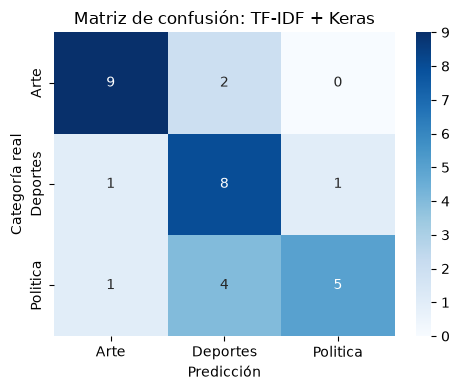

In [148]:
h1 = 32
h2 = 16
epocas = 50
lr = 0.005


for nombre_rep, (X_train, X_test) in matrices.items():
    print("\n" + "=" * 55)
    print("REPRESENTACIÓN:", nombre_rep)
    print("=" * 55)

    # Experimento 1 o 2: Scikit-learn
    nombre_sklearn = f"{nombre_rep} + Scikit-learn"

    modelo_sklearn = entrenar_sklearn(
        X_train, y_train,
        X_test, y_test,
        nombre_sklearn,        
        h1=h1, 
        h2=h2, 
        lr=lr, 
        batch_size=4, 
        max_iter=1, 
        epocas=epocas
    )
    # print(modelo_sklearn.get_params())

    # Experimento 3 o 4: TensorFlow/Keras
    nombre_keras = f"{nombre_rep} + Keras"

    X_train_dense = X_train.toarray().astype("float32")
    X_test_dense = X_test.toarray().astype("float32")

    modelo_keras = construir_mlp_keras(X_train.shape[1], h1=h1, h2=h2, lr=lr)
    #print(modelo_keras.summary())

    history = modelo_keras.fit(
        X_train_dense,
        y_train,
        epochs=epocas,
        batch_size=4,
        verbose=0,
        shuffle=True
    )

    probabilidades = modelo_keras.predict(
        X_test_dense,
        verbose=0
    )

    pred_test = np.argmax(probabilidades, axis=1)

    historicos[nombre_keras] = {
        "loss": history.history["loss"],
        "accuracy": history.history["accuracy"]
    }

    evaluar_modelo(nombre_keras, y_test, pred_test)


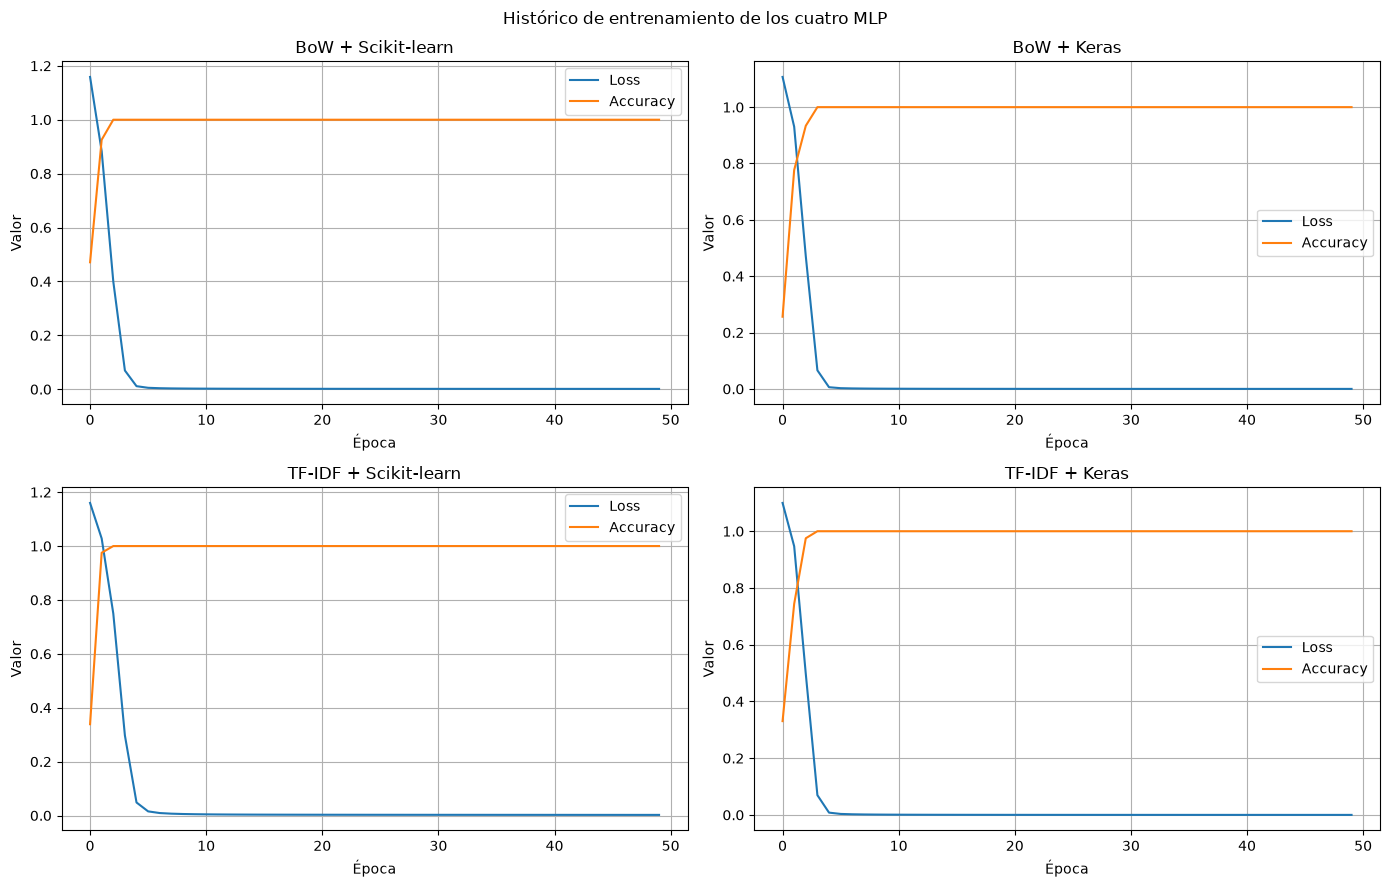

In [149]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (nombre, historial) in zip(
    axes.flatten(),
    historicos.items()
):
    ax.plot(historial["loss"], label="Loss")
    ax.plot(historial["accuracy"], label="Accuracy")
    ax.set_title(nombre)
    ax.set_xlabel("Época")
    ax.set_ylabel("Valor")
    ax.legend()
    ax.grid(True)

plt.suptitle("Histórico de entrenamiento de los cuatro MLP")
plt.tight_layout()
plt.show()


In [150]:
df_resultados = pd.DataFrame(resultados)

print(df_resultados.to_string(index=False))
display(df_resultados)



          Experimento  Accuracy  Precision   Recall  F1-score
   BoW + Scikit-learn  0.741935   0.777778 0.739394  0.734048
          BoW + Keras  0.774194   0.800595 0.766667  0.763980
TF-IDF + Scikit-learn  0.741935   0.777778 0.739394  0.734048
       TF-IDF + Keras  0.741935   0.777778 0.739394  0.734048
   BoW + Scikit-learn  0.741935   0.777778 0.739394  0.734048
          BoW + Keras  0.677419   0.690310 0.672727  0.671704
TF-IDF + Scikit-learn  0.741935   0.777778 0.739394  0.734048
       TF-IDF + Keras  0.709677   0.740981 0.706061  0.703283


,Experimento,Accuracy,Precision,Recall,F1-score
0,BoW + Scikit-learn,0.741935,0.777778,0.739394,0.734048
1,BoW + Keras,0.774194,0.800595,0.766667,0.763980
2,TF-IDF + Scikit-learn,0.741935,0.777778,0.739394,0.734048
3,TF-IDF + Keras,0.741935,0.777778,0.739394,0.734048
4,BoW + Scikit-learn,0.741935,0.777778,0.739394,0.734048
5,BoW + Keras,0.677419,0.690310,0.672727,0.671704
6,TF-IDF + Scikit-learn,0.741935,0.777778,0.739394,0.734048
7,TF-IDF + Keras,0.709677,0.740981,0.706061,0.703283


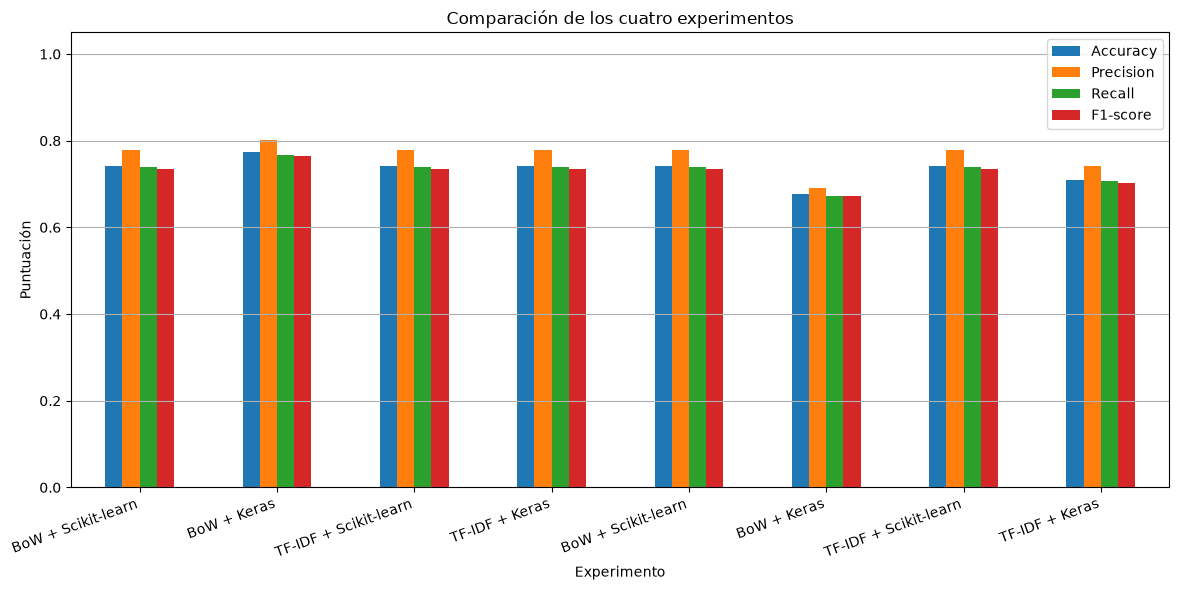

In [151]:
df_grafica = df_resultados.set_index("Experimento")

df_grafica[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05)
)

plt.title("Comparación de los cuatro experimentos")
plt.ylabel("Puntuación")
plt.xlabel("Experimento")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y")
plt.tight_layout()
# plt.show()



* Accuracy: proporción total de predicciones correctas.
* Precision: proporción de predicciones correctas entre las asignadas a una categoría.
* Recall: proporción de ejemplos de una categoría identificados correctamente.
* F1-score: media armónica de Precision y Recall.


Cambios sugeridos: 
* Cambiar las capas ocultas de (32, 16) a (64, 32).
* Comparar 50, 100 y 200 épocas.
* Probar tasas de aprendizaje de 0.001, 0.01 y 0.1.
* Comparar el uso de palabras vacías frente a no eliminarlas.
* Incorporar lematización y comparar los vocabularios.
* Aumentar el dataset a 300 o más frases.
* Incorporar validación cruzada estratificada para obtener una evaluación más estable.
* Desequilibrar las clases y verificar el comportamiento